# Prueba de concepto: reducción de la telemetría de un servidor Linux con PCA

**Proyecto:** Compresión y selección de variables de telemetría en servidores Linux utilizando Análisis de Componentes Principales (PCA)
**Autor:** Sean Sebastian Bolivar Calderon (20231020135)
**Curso:** Metodología de la Investigación, Universidad Distrital Francisco José de Caldas

**Pregunta de investigación:** ¿Es posible reducir las variables de monitoreo de un sistema Linux utilizando PCA, conservando la mayor parte de la información sobre su comportamiento?

**Hipótesis:** con $k \le 5$ componentes principales se conserva al menos el 90 % de la varianza de las métricas de `sar`.

Contenido:

1. Datos y entorno de recolección
2. Carga y preprocesamiento
3. Correlación entre métricas
4. Formulación matricial
5. Varianza explicada y elección de $k$
6. Cargas: qué representa cada componente
7. Proyección de las muestras
8. Reconstrucción
9. Líneas base
10. Discusión y conclusiones

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pca_telemetry import analysis, loading, plots, preprocessing

# Run from the repository root or from notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "results" / "figures"
TABLES_DIR = ROOT / "results" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.90
pd.set_option("display.precision", 4)


def save_table(table: pd.DataFrame, name: str) -> pd.DataFrame:
    table.to_csv(TABLES_DIR / f"{name}.csv", index=False)
    return table

## 1. Datos y entorno de recolección

Los datos se recolectaron en una máquina virtual Debian 13 (KVM) alojada en un servidor Proxmox local, que emula un VPS de 2 vCPU y 7,8 GiB de RAM. Se usó `sar` (sysstat) con una muestra por segundo mientras `stress-ng` generaba cinco escenarios de carga de 30 minutos cada uno, con pausas de 60 s entre ellos:

| Escenario | Carga generada |
|---|---|
| `idle` | Sin carga (reposo) |
| `cpu` | `stress-ng --cpu 0`: todos los núcleos al 100 % |
| `memory` | `stress-ng --vm 1 --vm-bytes 75%`: ocupa el 75 % de la RAM |
| `disk` | `stress-ng --hdd 2 --hdd-opts direct`: escritura y lectura directa a disco |
| `network` | `stress-ng --sock 2`: tráfico TCP por la interfaz de loopback |

Los scripts están en `collection/` y los CSV exportados con `sadf` en `data/raw/`.

In [2]:
print((RAW_DIR / "server_specs.txt").read_text().split("## Disks")[0])

# Server specifications
date: 2026-11-02T13:04:59-05:00

## Kernel
Linux serv-debian 6.12.107+deb13-amd64 #1 SMP PREEMPT_DYNAMIC Debian 6.12.107-1 (2026-08-29) x86_64 GNU/Linux

## OS
PRETTY_NAME="Debian GNU/Linux 13 (trixie)"
NAME="Debian GNU/Linux"
VERSION_ID="13"
VERSION="13 (trixie)"

## CPU
Architecture:                            x86_64
CPU op-mode(s):                          32-bit, 64-bit
Address sizes:                           40 bits physical, 48 bits virtual
Byte Order:                              Little Endian
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Vendor ID:                               GenuineIntel
Model name:                              QEMU Virtual CPU version 2.5+
CPU family:                              15
Model:                                   107
Thread(s) per core:                      1
Core(s) per socket:                      2
Socket(s):                               1
Stepping:                             

In [3]:
pd.read_csv(RAW_DIR / "run_log.csv")

,scenario,start_epoch,end_epoch,duration_s,interval_s,samples
0,idle,1793642699,1793644499,1800,1,1800
1,cpu,1793644559,1793646360,1800,1,1800
2,memory,1793646420,1793648220,1800,1,1800
3,disk,1793648280,1793650080,1800,1,1800
4,network,1793650140,1793651941,1800,1,1800


## 2. Carga y preprocesamiento

Cada escenario tiene un CSV por grupo de métricas (`cpu`, `mem`, `io`, `task`, `net`). Se unen por `timestamp`, de modo que cada fila es un instante de muestreo y cada columna una métrica. El tráfico de red se suma sobre todas las interfaces.

La columna `scenario` **no** entra al PCA, que es no supervisado. Solo se usa para interpretar los resultados y para las líneas base.

In [4]:
data = loading.load_dataset(RAW_DIR)
loading.save_dataset(data, PROCESSED_DIR / "telemetry.csv")
print(data.shape)
data.groupby("scenario", observed=True).size().rename("samples").to_frame()

(9000, 32)


,samples
scenario,
idle,1800
cpu,1800
memory,1800
disk,1800
network,1800


Pasos del preprocesamiento:

1. **Transitorios:** se eliminan los primeros y últimos 5 s de cada escenario, porque mientras la carga arranca o se detiene el servidor no está en ninguno de los dos estados.
2. **Limpieza:** se eliminan las filas con valores faltantes o duplicadas.
3. **Métricas constantes:** una métrica que no varía no aporta información y no se puede estandarizar.
4. **Estandarización z-score:** las métricas tienen unidades muy distintas (%, kB, paquetes/s). Sin estandarizar, las de valores grandes (como `kbmemfree`, del orden de $10^6$) dominarían las componentes.

$$ z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j} $$

In [5]:
X, Xz, y, report = preprocessing.prepare(data, trim_seconds=5)
summary = {key: value for key, value in report.items() if key != "scaler"}
summary["n_metrics"] = X.shape[1]
pd.Series(summary, name="value").to_frame()

,value
rows_before,8950
missing_removed,0
duplicates_removed,0
rows_after,8950
transient_rows_removed,50
constant_metrics,"[%nice, dtps, bdscd/s]"
n_metrics,27


In [6]:
X.groupby(y.values).mean().T

,idle,cpu,memory,disk,network
%user,1.1666e-01,9.9939e+01,5.0108e+01,5.7067e+00,2.0629e+01
%system,1.4460e-01,5.6972e-02,2.3039e-01,1.1286e+01,7.9365e+01
%iowait,1.9223e-01,0.0000e+00,1.4628e-01,8.2339e+01,0.0000e+00
%steal,3.6313e-03,3.0670e-03,3.6201e-03,6.6145e-03,4.1899e-03
%idle,9.9543e+01,5.5866e-04,4.9511e+01,6.6267e-01,1.9553e-03
kbmemfree,7.1846e+06,7.1539e+06,1.7613e+06,7.1138e+06,7.1418e+06
kbavail,7.4644e+06,7.4490e+06,2.0712e+06,7.4367e+06,7.4777e+06
kbmemused,3.9951e+05,3.9771e+05,5.7748e+06,4.0898e+05,3.6755e+05
%memused,4.9087e+00,4.8869e+00,7.0956e+01,5.0251e+00,4.5173e+00
kbbuffers,3.6523e+04,3.9305e+04,4.2121e+04,4.5441e+04,4.8729e+04


## 3. Correlación entre métricas

Si muchas métricas están fuertemente correlacionadas, comparten información y se pueden resumir en pocas componentes. Esta es la motivación del PCA.

Metric pairs: 729
Pairs with |r| > 0.9: 42
Pairs with |r| > 0.7: 60


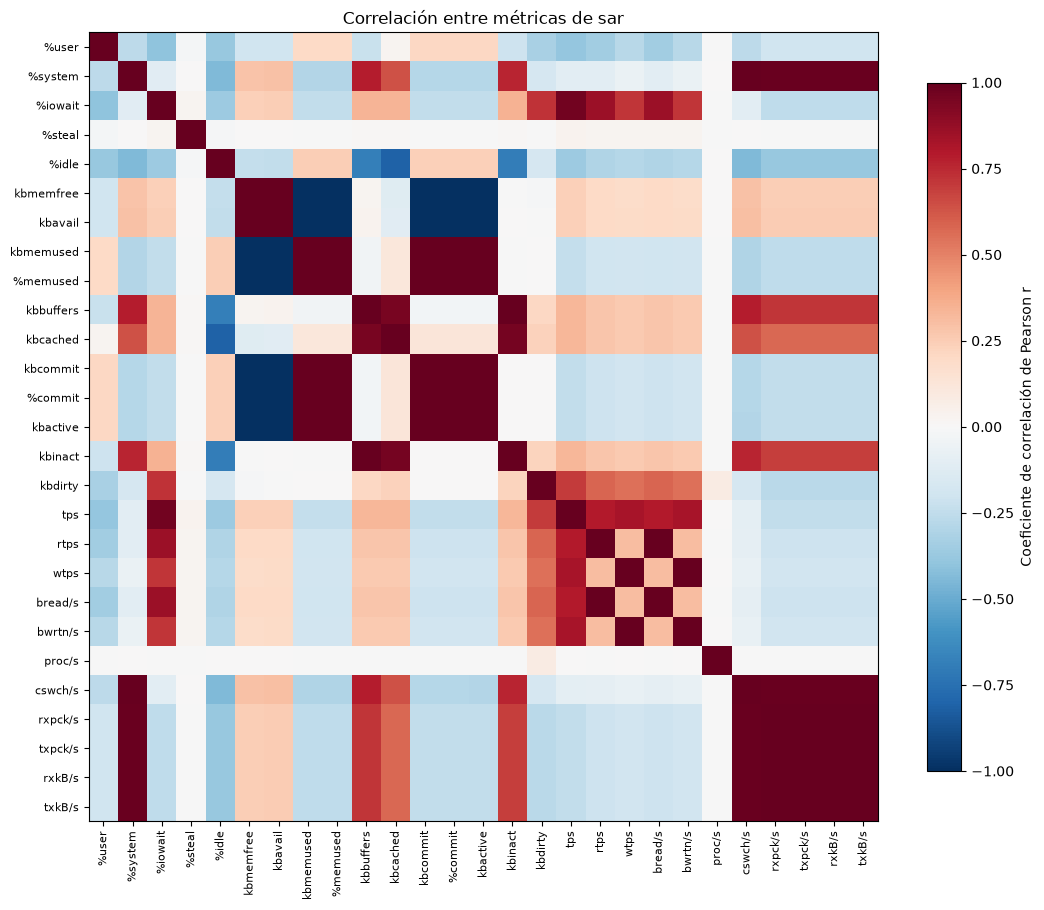

In [7]:
corr = Xz.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Metric pairs: {len(upper)}")
print(f"Pairs with |r| > 0.9: {(upper.abs() > 0.9).sum()}")
print(f"Pairs with |r| > 0.7: {(upper.abs() > 0.7).sum()}")

fig = plots.plot_correlation(Xz)
plots.save_figure(fig, "correlation_matrix", FIGURES_DIR)
plt.show()

## 4. Formulación matricial

Sea $X_z \in \mathbb{R}^{N \times P}$ la matriz estandarizada ($N$ instantes, $P$ métricas). PCA calcula la matriz de covarianza y su descomposición en valores y vectores propios:

$$ \Sigma = \frac{1}{N-1} X_z^\top X_z = W \Lambda W^\top, \qquad \lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_P $$

Cada vector propio $w_i$ (columna de $W$) es una componente principal, y su valor propio $\lambda_i$ es la varianza que explica. Tomando las primeras $k$ columnas, $W_k \in \mathbb{R}^{P \times k}$:

- **Varianza explicada acumulada:** $\displaystyle \text{VEA}(k) = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{P} \lambda_i}$
- **Proyección (compresión):** $Z = X_z W_k \in \mathbb{R}^{N \times k}$
- **Reconstrucción:** $\hat{X}_z = Z W_k^\top$
- **Error relativo:** $\displaystyle e(k) = \frac{\lVert X_z - \hat{X}_z \rVert_F}{\lVert X_z \rVert_F}$

Como verificación, la descomposición de $\Sigma$ calculada a mano coincide con la de scikit-learn:

In [8]:
N, P = Xz.shape
sigma = Xz.to_numpy().T @ Xz.to_numpy() / (N - 1)
eigenvalues, eigenvectors = np.linalg.eigh(sigma)
eigenvalues = eigenvalues[::-1]

pca = analysis.fit_pca(Xz)

print(f"N = {N} samples, P = {P} metrics")
print(f"Sigma shape: {sigma.shape}")
print("Eigenvalues match sklearn:", np.allclose(eigenvalues, pca.explained_variance_))
print(f"Sum of eigenvalues = trace(Sigma) = {eigenvalues.sum():.3f}")

N = 8950 samples, P = 27 metrics
Sigma shape: (27, 27)
Eigenvalues match sklearn: True
Sum of eigenvalues = trace(Sigma) = 27.003


## 5. Varianza explicada y elección de $k$

Se busca el menor $k$ tal que $\text{VEA}(k)$ alcance el umbral. Se reportan los umbrales de 80, 90 y 95 %.

In [9]:
variance = save_table(analysis.variance_table(pca), "variance_table")
variance.head(10)

,component,eigenvalue,explained_variance,cumulative_variance
0,PC1,9.3569,0.3465,0.3465
1,PC2,6.8575,0.2540,0.6005
2,PC3,5.3403,0.1978,0.7982
3,PC4,1.5253,0.0565,0.8547
4,PC5,1.3924,0.0516,0.9063
5,PC6,1.0121,0.0375,0.9438
6,PC7,0.9979,0.0370,0.9807
7,PC8,0.3973,0.0147,0.9954
8,PC9,0.0922,0.0034,0.9988
9,PC10,0.0284,0.0011,0.9999


In [10]:
components = save_table(analysis.components_table(pca), "components_per_threshold")
components

,threshold,k,n_metrics,reduction_ratio,cumulative_variance
0,0.80,4,27,0.1481,0.8547
1,0.90,5,27,0.1852,0.9063
2,0.95,7,27,0.2593,0.9807


k = 5 of P = 27 metrics (18.5%) keeps 90.63% of the variance


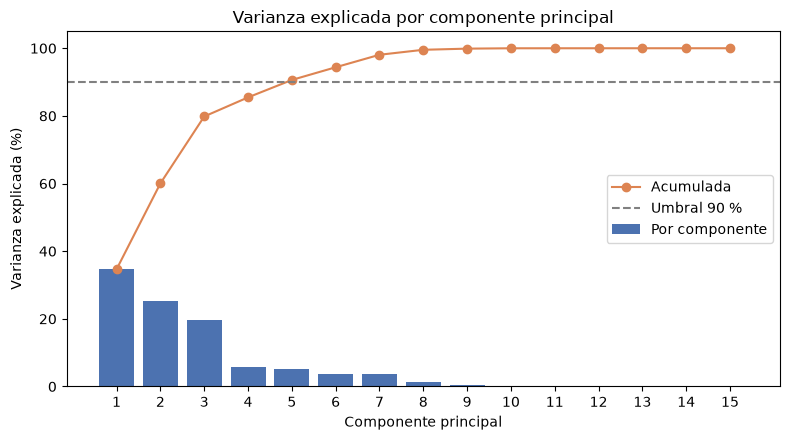

In [11]:
k = analysis.n_components_for(pca, THRESHOLD)
print(f"k = {k} of P = {P} metrics ({k / P:.1%}) keeps "
      f"{variance['cumulative_variance'].iloc[k - 1]:.2%} of the variance")

fig = plots.plot_scree(pca, threshold=THRESHOLD, max_components=15)
plots.save_figure(fig, "scree_cumulative_variance", FIGURES_DIR)
plt.show()

## 6. Cargas: qué representa cada componente

Las cargas son los pesos de cada métrica en cada componente (las columnas de $W_k$). Una carga con valor absoluto grande indica que la métrica define esa componente; el signo indica si sube o baja con ella. Así se puede interpretar cada componente como un "subsistema" del servidor.

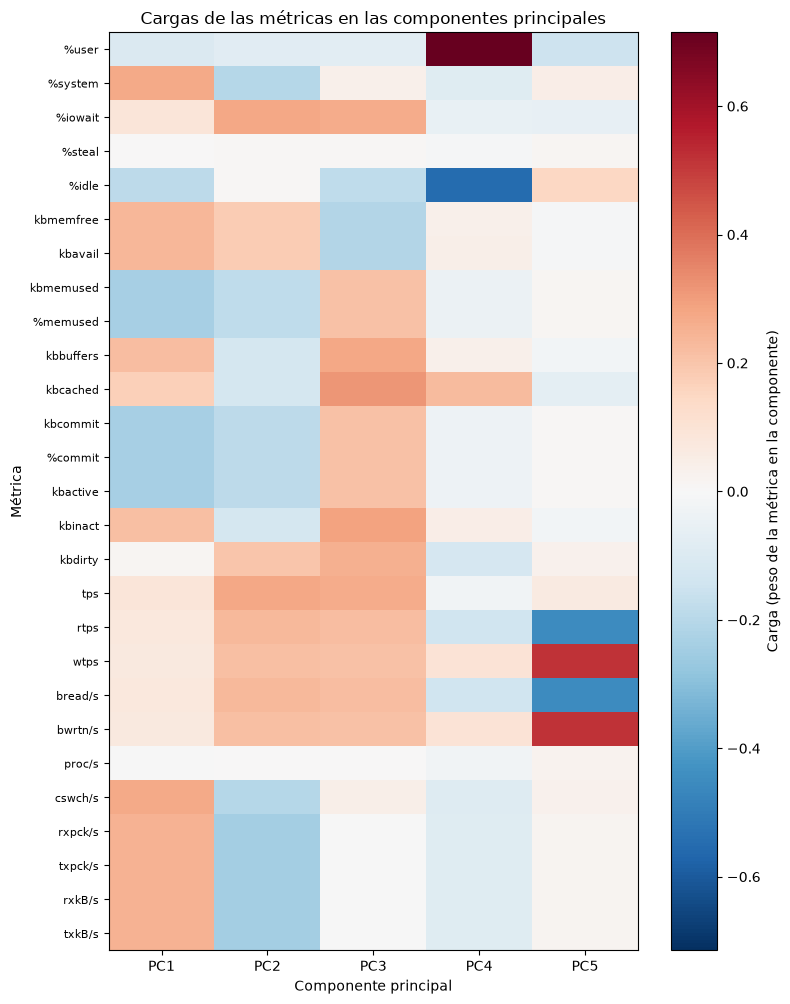

In [12]:
load = analysis.loadings(pca, Xz.columns, k)
save_table(load.reset_index(names="metric"), "loadings")

fig = plots.plot_loadings(load)
plots.save_figure(fig, "loadings", FIGURES_DIR)
plt.show()

In [13]:
dominant = save_table(analysis.dominant_metrics(load, n=3), "dominant_metrics")
dominant

,component,rank,metric,loading
0,PC1,1,cswch/s,0.2709
1,PC1,2,%system,0.2699
2,PC1,3,rxkB/s,0.2509
3,PC2,1,tps,0.2764
4,PC2,2,%iowait,0.2759
5,PC2,3,txpck/s,-0.2404
6,PC3,1,kbcached,0.3152
7,PC3,2,kbinact,0.2871
8,PC3,3,kbbuffers,0.2761
9,PC4,1,%user,0.7149


## 7. Proyección de las muestras

Cada segundo de telemetría, que originalmente es un punto en $\mathbb{R}^{P}$, se proyecta en las dos primeras componentes. El color (escenario) no se usó para calcular el PCA. Si los escenarios aparecen separados, el espacio reducido conserva el comportamiento del servidor.

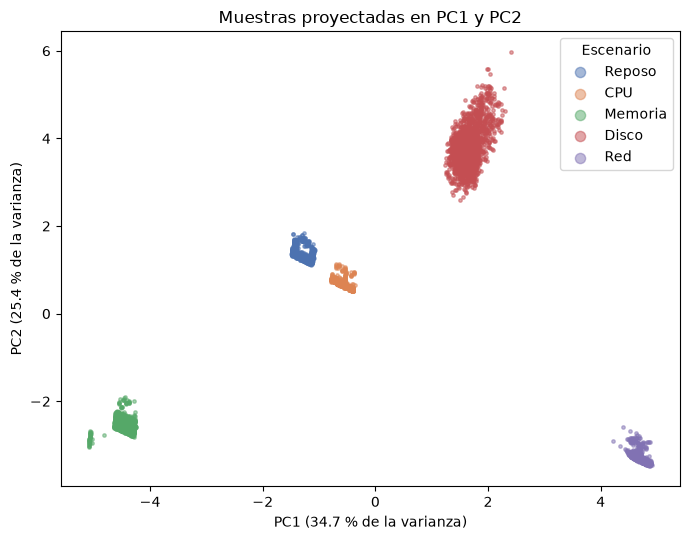

In [14]:
Z = analysis.project(Xz, pca, k)

fig = plots.plot_projection(Z, y, pca)
plots.save_figure(fig, "projection_pc1_pc2", FIGURES_DIR)
plt.show()

## 8. Reconstrucción

Si $k$ componentes conservan la información, a partir de $Z$ (de tamaño $N \times k$) se deben poder recuperar las $P$ métricas originales con poco error.

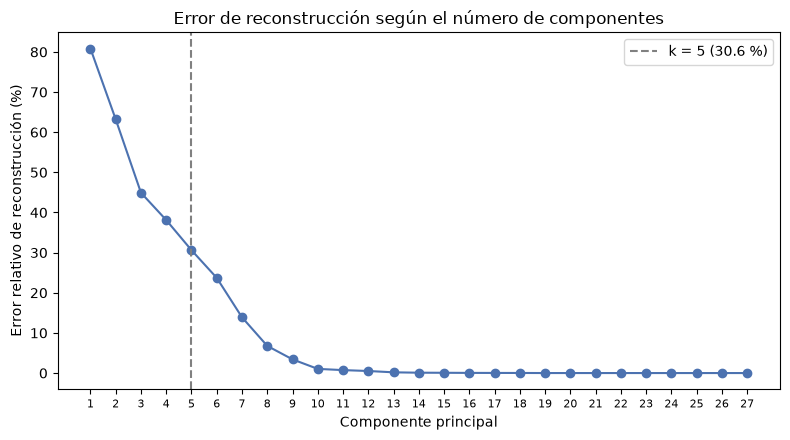

,k,relative_error
0,1,0.8084
1,2,0.6321
2,3,0.4492
3,4,0.3812
4,5,0.3061
5,6,0.2371
6,7,0.1389
7,8,0.0676
8,9,0.0341
9,10,0.0104


In [15]:
curve = save_table(analysis.reconstruction_curve(Xz, pca), "reconstruction_curve")

fig = plots.plot_reconstruction_curve(curve, k=k)
plots.save_figure(fig, "reconstruction_curve", FIGURES_DIR)
plt.show()

curve.head(10)

Para ver el resultado en unidades reales, se reconstruye una métrica con $k$ componentes y se deshace la estandarización ($x = z \cdot s_j + \bar{x}_j$). El eje de tiempo concatena los cinco escenarios.

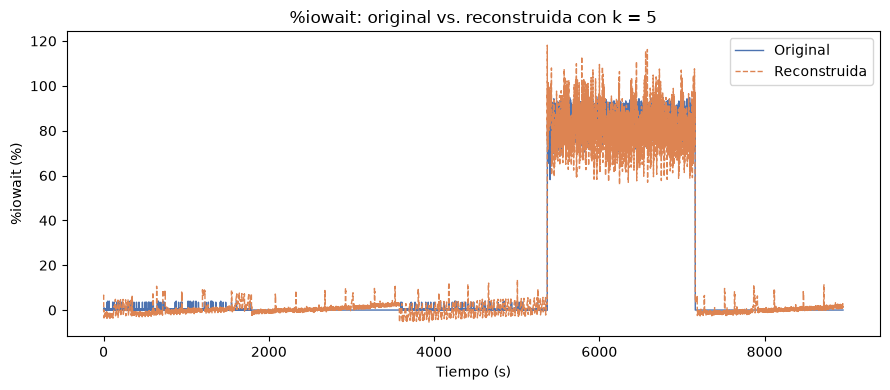

,metric,relative_error
5,kbmemfree,0.0237
13,kbactive,0.0240
11,kbcommit,0.0244
12,%commit,0.0244
7,kbmemused,0.0245
8,%memused,0.0245
6,kbavail,0.0245
23,rxpck/s,0.0542
24,txpck/s,0.0542
25,rxkB/s,0.0544


In [16]:
scaler = report["scaler"]
Xz_hat = analysis.reconstruct(Xz, pca, k)
X_hat = pd.DataFrame(scaler.inverse_transform(Xz_hat), index=X.index, columns=X.columns)

per_metric = pd.DataFrame({
    "metric": X.columns,
    "relative_error": [analysis.relative_error(Xz[c], Xz_hat[c]) for c in X.columns],
}).sort_values("relative_error")
save_table(per_metric, "reconstruction_error_per_metric")

metric = "%iowait"
fig = plots.plot_reconstruction(X[metric], X_hat[metric], metric, k)
plots.save_figure(fig, "reconstruction_iowait", FIGURES_DIR)
plt.show()

per_metric

## 9. Líneas base

Para saber si PCA aporta algo frente a alternativas más simples, se compara con tres líneas base.

### 9.1 Filtro de correlación

Es la alternativa más común: descartar una métrica si tiene $|r| > 0{,}9$ con alguna ya conservada. Las métricas descartadas se reconstruyen por mínimos cuadrados a partir de las conservadas. Para que la comparación sea justa, PCA usa el mismo número de dimensiones que métricas conserva el filtro.

In [17]:
subset = analysis.correlation_filter(Xz, threshold=0.9)
print(f"Correlation filter keeps {len(subset)} of {P} metrics:")
print(subset)

reconstruction = save_table(analysis.compare_reconstruction(Xz, pca, threshold=0.9),
                            "baseline_reconstruction")
reconstruction

Correlation filter keeps 11 of 27 metrics:
['%user', '%system', '%iowait', '%steal', '%idle', 'kbmemfree', 'kbbuffers', 'kbdirty', 'rtps', 'wtps', 'proc/s']


,method,k,relative_error
0,pca,11,0.0073
1,correlation_filter(|r|>0.9),11,0.0188


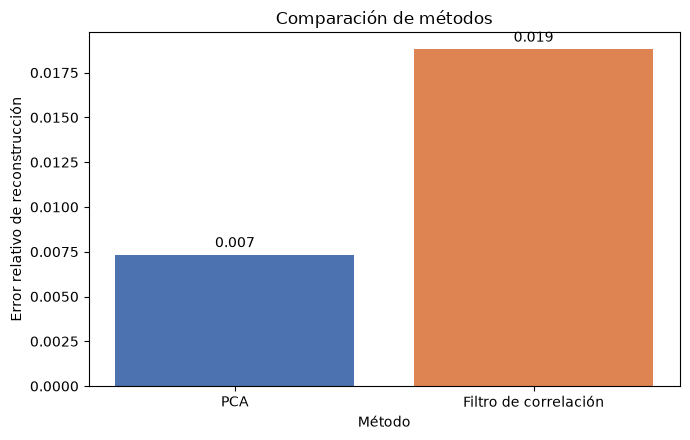

In [18]:
fig = plots.plot_method_comparison(reconstruction, "relative_error",
                                   "Error relativo de reconstrucción")
plots.save_figure(fig, "baseline_reconstruction", FIGURES_DIR)
plt.show()

### 9.2 Clasificador del escenario de carga

Una regresión logística intenta predecir el escenario a partir de las $P$ métricas, de las $k$ componentes o del subconjunto del filtro. Si con $k$ componentes la exactitud se mantiene, la reducción no perdió la información que distingue los comportamientos.

La validación cruzada usa **bloques contiguos de tiempo**. Dos segundos consecutivos son casi idénticos, así que con particiones aleatorias el modelo vería en el entrenamiento muestras casi iguales a las de prueba y la exactitud quedaría inflada. La estandarización y el PCA se ajustan dentro de cada partición.

In [19]:
classifiers = save_table(analysis.compare_classifiers(X, y, k, subset=subset),
                         "baseline_classifier")
classifiers

,method,n_features,accuracy_mean,accuracy_std,n_folds
0,all_metrics,27,1.0,0.0,5
1,pca,5,1.0,0.0,5
2,correlation_subset,11,1.0,0.0,5


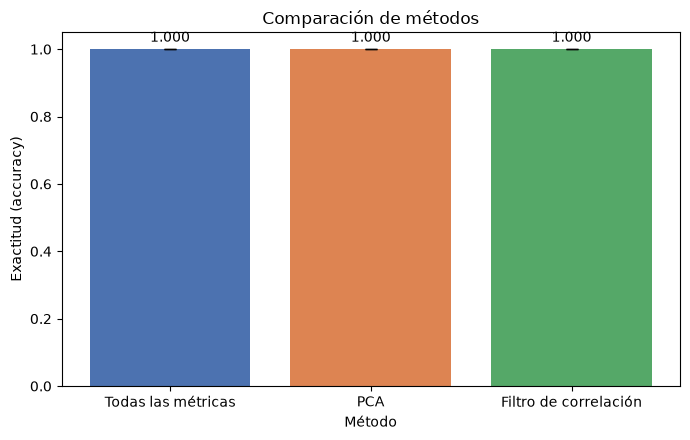

In [20]:
fig = plots.plot_method_comparison(classifiers, "accuracy_mean", "Exactitud (accuracy)",
                                   error="accuracy_std")
plots.save_figure(fig, "baseline_classifier", FIGURES_DIR)
plt.show()

### 9.3 Agrupamiento (K-Means)

Como en Lee et al. (2023), se aplica K-Means con 5 grupos sobre todas las métricas y sobre las $k$ componentes, sin usar las etiquetas:

- **Silhouette** (de −1 a 1): qué tan separados y compactos quedan los grupos.
- **ARI** (*Adjusted Rand Index*, 0 ≈ azar, 1 = perfecto): qué tanto coinciden los grupos con los escenarios reales.

In [21]:
clustering = save_table(analysis.compare_clustering(Xz, pca, k, y), "baseline_clustering")
clustering

,method,n_features,silhouette,adjusted_rand_index
0,all_metrics,27,0.7756,1.0
1,pca,5,0.8594,1.0


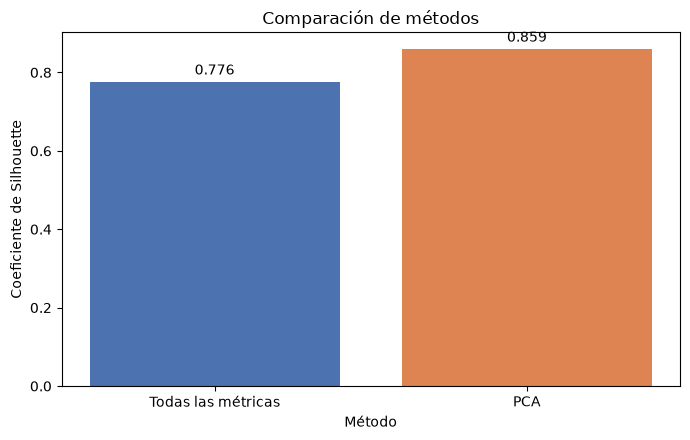

In [22]:
fig = plots.plot_method_comparison(clustering, "silhouette", "Coeficiente de Silhouette")
plots.save_figure(fig, "baseline_clustering", FIGURES_DIR)
plt.show()

## 10. Discusión y conclusiones

In [23]:
row = components.set_index("threshold").loc[THRESHOLD]
results = pd.Series({
    "metrics_P": P,
    "components_k": k,
    "reduction_k_over_P": k / P,
    "cumulative_variance": row["cumulative_variance"],
    "reconstruction_error_k": curve.loc[curve["k"] == k, "relative_error"].iloc[0],
    "pca_error_same_dim_as_filter": reconstruction["relative_error"].iloc[0],
    "filter_error": reconstruction["relative_error"].iloc[1],
    "accuracy_all_metrics": classifiers["accuracy_mean"].iloc[0],
    "accuracy_pca": classifiers["accuracy_mean"].iloc[1],
    "silhouette_all_metrics": clustering["silhouette"].iloc[0],
    "silhouette_pca": clustering["silhouette"].iloc[1],
    "ari_pca": clustering["adjusted_rand_index"].iloc[1],
}, name="value")
save_table(results.rename_axis("result").reset_index(), "summary")
results.to_frame()

,value
metrics_P,27.0000
components_k,5.0000
reduction_k_over_P,0.1852
cumulative_variance,0.9063
reconstruction_error_k,0.3061
pca_error_same_dim_as_filter,0.0073
filter_error,0.0188
accuracy_all_metrics,1.0000
accuracy_pca,1.0000
silhouette_all_metrics,0.7756


### Resultados cuantitativos

- Después de eliminar 3 métricas constantes (`%nice`, `dtps`, `bdscd/s`) quedan **P = 27** métricas.
- **k = 5** componentes conservan el **90,6 %** de la varianza, es decir, el 18,5 % de las dimensiones originales. Para el 80 % bastan 4 componentes y para el 95 % se necesitan 7.
- Con $k = 5$ el error relativo de reconstrucción es $e(5) = 30{,}6\ \%$. Este valor está en norma de Frobenius, así que corresponde a $\sqrt{1 - 0{,}906}$, es decir, al 9,4 % de varianza que no se conserva. El error baja a 13,9 % con $k = 7$ y a 1 % con $k = 10$.
- Por métrica, las de memoria se reconstruyen con un error de alrededor del 2 % y las de red con 5 %. Las peor reconstruidas son `%steal` y `proc/s` (≈ 100 %) y `kbdirty` (60 %): son casi constantes y su variación es ruido que no comparte información con el resto, por eso PCA las descarta. Son candidatas a dejar de monitorearse.
- Con la misma dimensión (11), PCA reconstruye las métricas con un error relativo de **0,73 %**, frente a **1,88 %** del filtro de correlación: alrededor de 2,5 veces menor.
- El clasificador alcanza una exactitud del **100 %** con las 27 métricas, con las 5 componentes y con el subconjunto del filtro.
- K-Means recupera los cinco escenarios con ARI = 1 en ambos casos, y el Silhouette **mejora** de 0,78 a 0,86 al usar las 5 componentes.

### Resultados cualitativos

Cada componente se puede interpretar como un subsistema del servidor:

| Componente | Métricas dominantes | Interpretación |
|---|---|---|
| PC1 | `cswch/s`, `%system`, `rxkB/s` | Red y trabajo del kernel |
| PC2 | `tps`, `%iowait` | Disco |
| PC3 | `kbcached`, `kbinact`, `kbbuffers` | Memoria y caché de páginas |
| PC4 | `%user` frente a `%idle` | CPU en espacio de usuario |
| PC5 | `wtps`, `bwrtn/s` frente a `rtps` | Escritura frente a lectura en disco |

En la proyección PC1 vs PC2 los escenarios de red y disco se separan con claridad del resto.

### Limitaciones

1. **Escenarios sintéticos muy diferentes.** Cada carga satura un solo recurso, por eso el clasificador llega al 100 % con cualquier representación. Esto confirma que las 5 componentes no pierden la información necesaria para distinguir los escenarios, pero no permite ordenar los métodos. Una carga real mezcla recursos y sería una prueba más exigente.
2. **Tendencia temporal en la memoria.** `kbcached`, `kbbuffers` y `kbinact` crecen de un escenario al siguiente porque el caché de páginas se acumula durante la recolección. Como los escenarios se ejecutaron en orden, una parte de PC3 refleja el momento de la medición y no la carga.
3. **Un solo servidor** virtualizado, con 2 vCPU y una sola corrida por escenario.
4. **PCA es lineal.** Las relaciones no lineales entre métricas no se capturan.

### Conclusión

Sí es posible reducir las variables de monitoreo de un servidor Linux con PCA conservando la mayor parte de la información sobre su comportamiento. En este experimento, 5 componentes resumen 27 métricas de `sar` conservando el 90,6 % de la varianza, **lo que confirma la hipótesis**. Además, permiten distinguir los cinco escenarios de carga sin pérdida. Frente a la selección de métricas por correlación, PCA reconstruye mejor la información con el mismo número de dimensiones, y sus componentes tienen una interpretación clara en términos de subsistemas (red, disco, memoria y CPU).

**Trabajo futuro:** cargas mixtas y reales, varias corridas con un orden aleatorio de escenarios, más servidores y la aplicación en `app/` para monitorear en tiempo real con las componentes.